## 04 · Fixing the Score

Notebook 03 showed an agent that learned to cut households off because its scoring rule made that free. This notebook changes the scoring rule so that it reflects the actual goal, retrains the same agent from scratch on it, and compares the result fairly against the rulebook.

### What changed in the scoring rule

- **Shed load now counts as undelivered energy**, at the same $2 per kWh as any other unmet demand. Cutting households off is no longer free.
- **Running diesel while the sun is up costs extra.** Whenever solar output is above 5 kW, the generator is charged an additional penalty equal to the fuel cost of the solar energy available, so burning diesel in daylight is roughly twice as expensive.
- **The generator's $0.50 start-up cost is charged once per start**, not every hour it runs (an accounting correction).

Everything else (the grid, the agent, its training settings) is identical to notebook 03.

In [1]:
# Load plotting, environment, agents and helpers; train the agent on the corrected reward (or load it)
from pathlib import Path
import matplotlib.pyplot as plt
from minigrid_mdp.env.minigrid_env import MiniGridEnv
from minigrid_mdp.agents import RuleBasedAgent, DRLAgent
from minigrid_mdp.metrics import run_days, summarise, compare, action_share_by_hour
from minigrid_mdp.plotting import plot_day
from minigrid_mdp.training import train_or_load

MODELS_DIR = Path("..") / "models"
FIXED_MODEL_PATH = MODELS_DIR / "ppo_fixed_reward.zip"

train_or_load(MiniGridEnv, FIXED_MODEL_PATH)

### The rematch

Same 20 days as notebook 02, same corrected scoring rule for both operators.

In [2]:
# Evaluate the retrained AI and the rulebook over the same 20 days under the corrected reward
env = MiniGridEnv()
fixed_agent = DRLAgent(env.action_space, model_path=str(FIXED_MODEL_PATH))

fixed_log = run_days(env, fixed_agent)
results = {
    "rulebook": summarise(run_days(env, RuleBasedAgent(env.action_space))),
    "ai_fixed_reward": summarise(fixed_log),
}
compare(results)

rulebook       ai_fixed_reward      
                     mean   std            mean   std
diesel_hours_pct    38.96  2.04           25.62  1.53
fuel_cost_usd       33.52  1.61           29.26  2.00
unmet_pct            0.08  0.28            0.06  0.17
end_soc              0.33  0.06            0.36  0.12
reward             -34.38  3.04          -30.16  2.38

**What this shows:** with a scoring rule that reflects the real goal, the AI beats the rulebook honestly. Over the same 20 days it spends about 13% less on fuel ($29.26 vs $33.52 a day), runs the generator for a third fewer hours, and serves the village just as reliably (under 0.1% of demand unmet for both). It also ends each day with slightly more energy in the battery than the rulebook does, so its savings aren't coming from draining stored energy harder.

Fuel cost, not generator hours, is the fairer headline: the AI runs diesel for fewer hours, but not all hours burn the same amount of fuel.


In [3]:
# Show which action the retrained AI picks at each hour of the day
action_share_by_hour(fixed_log)

action,discharge_battery,run_diesel_only,solar_only
hour,,,
0,0.00,1.00,0.00
1,0.00,1.00,0.00
2,1.00,0.00,0.00
3,0.90,0.00,0.10
4,0.00,0.00,1.00
5,0.00,0.00,1.00
6,0.00,0.00,1.00
7,0.00,0.00,1.00
8,0.00,0.00,1.00


**What this shows:** in the evening, the AI behaves almost exactly like the rulebook: battery around 7 pm, then diesel through to midnight. The difference is at night. The rulebook runs the generator for six hours before dawn at near-minimum output, partly recharging the battery with diesel. The AI runs the generator only at midnight and 1 am, while demand is still high, then lets the battery carry the quiet hours before sunrise.

*Note on reading this table:* `solar_only` before sunrise doesn't mean the sun is up. It means "solar covers what it can, the battery covers the rest", and with almost no solar, that's simply running on the battery. At night, `solar_only` and `discharge_battery` behave identically, which is why the AI switches between them freely.


In [7]:
# At 4am on each day, show the action chosen and the actual energy flows
at_4am = fixed_log[fixed_log.hour == 4].assign(day=lambda d: d.episode + 1).set_index("day")
at_4am[["action", "pv_kw", "load_kw", "battery_kw", "diesel_kw"]].head()

,action,pv_kw,load_kw,battery_kw,diesel_kw
day,,,,,
1,3,0.397,7.439,7.042,0.0
2,3,0.469,9.081,8.612,0.0
3,3,0.463,8.188,7.725,0.0
4,3,0.387,12.269,11.882,0.0
5,3,0.337,9.026,8.689,0.0


In [4]:
# Compare wasted solar per day: solar that was available but neither used nor stored
def wasted_solar_per_day(log):
    wasted = log.curtailed_kw.where(log.action != 4, 0.0)
    return wasted.groupby(log.episode).sum().mean()

rulebook_log = run_days(env, RuleBasedAgent(env.action_space))
print(f"Wasted solar per day | rulebook: {wasted_solar_per_day(rulebook_log):.1f} kWh | AI: {wasted_solar_per_day(fixed_log):.1f} kWh")

Wasted solar per day | rulebook: 95.8 kWh | AI: 72.2 kWh


**What this shows:** in the evening, the AI behaves almost exactly like the rulebook: battery around 7 pm, then diesel through to midnight. The difference is at night. The rulebook runs the generator for six hours before dawn at near-minimum output, partly recharging the battery with diesel. The AI runs the generator only at midnight and 1 am, while demand is still high, then lets the battery carry the quiet hours before sunrise.

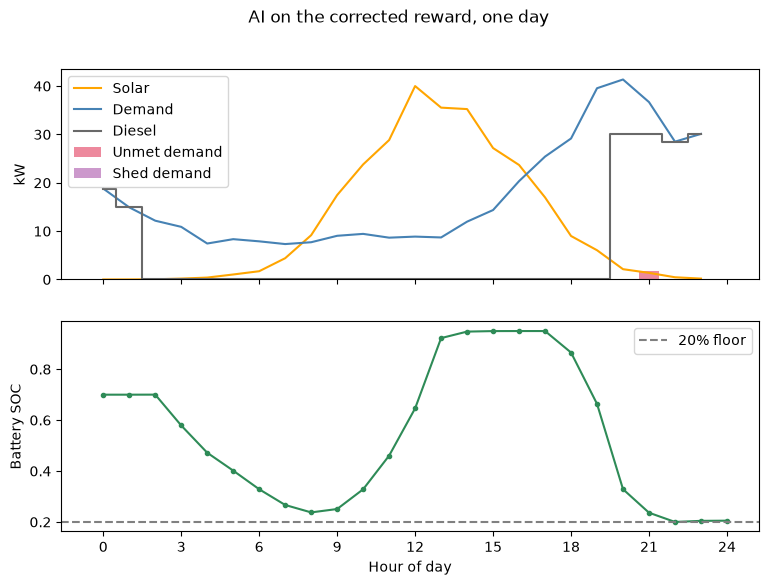

In [5]:
# Plot one day (seed 0) of the retrained AI, for direct comparison with the rulebook in notebook 02
plot_day(fixed_log[fixed_log.episode == 0], env.bat_cfg["initial_soc"], env.bat_cfg["min_soc"], title="AI on the corrected reward, one day")
plt.show()

**What this shows:** compared with the rulebook on the same day (notebook 02), the evening is almost identical. The difference is the morning. The AI runs the generator only for the first two hours after midnight, then lets the battery carry the village until sunrise, arriving with the battery at 24% instead of the rulebook's 48%. Both batteries are full by 1 pm, but the AI's started emptier, so it stored about 24 kWh more of the morning's solar. That stored sunshine is the diesel it didn't burn.

## Summary

- With a scoring rule that counts shed load as undelivered energy, the retrained AI no longer cuts households off.
- Over the same 20 days it spends about **13% less on fuel** than the rulebook ($29.26 vs $33.52 a day), at the same reliability.
- The saving comes from the morning, not the evening: the AI empties the battery before sunrise so it can store more solar, wasting about 24 kWh less per day.
- Both operators still waste a quarter to a third of the day's solar. That limit comes from the battery's size, not how it's operated.

**Next:** both operators end each day with less energy in the battery than they started with. Notebook 05 charges them for it and checks whether the AI's advantage survives.